# Introduction

This notebook replicates all main text and supplementary figures (except Fig. 1, which is a schematic and was done in using Inkscape) of manuscript "Detecting emergent impact niches from microbial community microenvironments".

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
from scripts import *

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.gridspec import GridSpec
from matplotlib.colors import TwoSlopeNorm
from matplotlib.lines import Line2D

# Figure 2

## Figure 2a

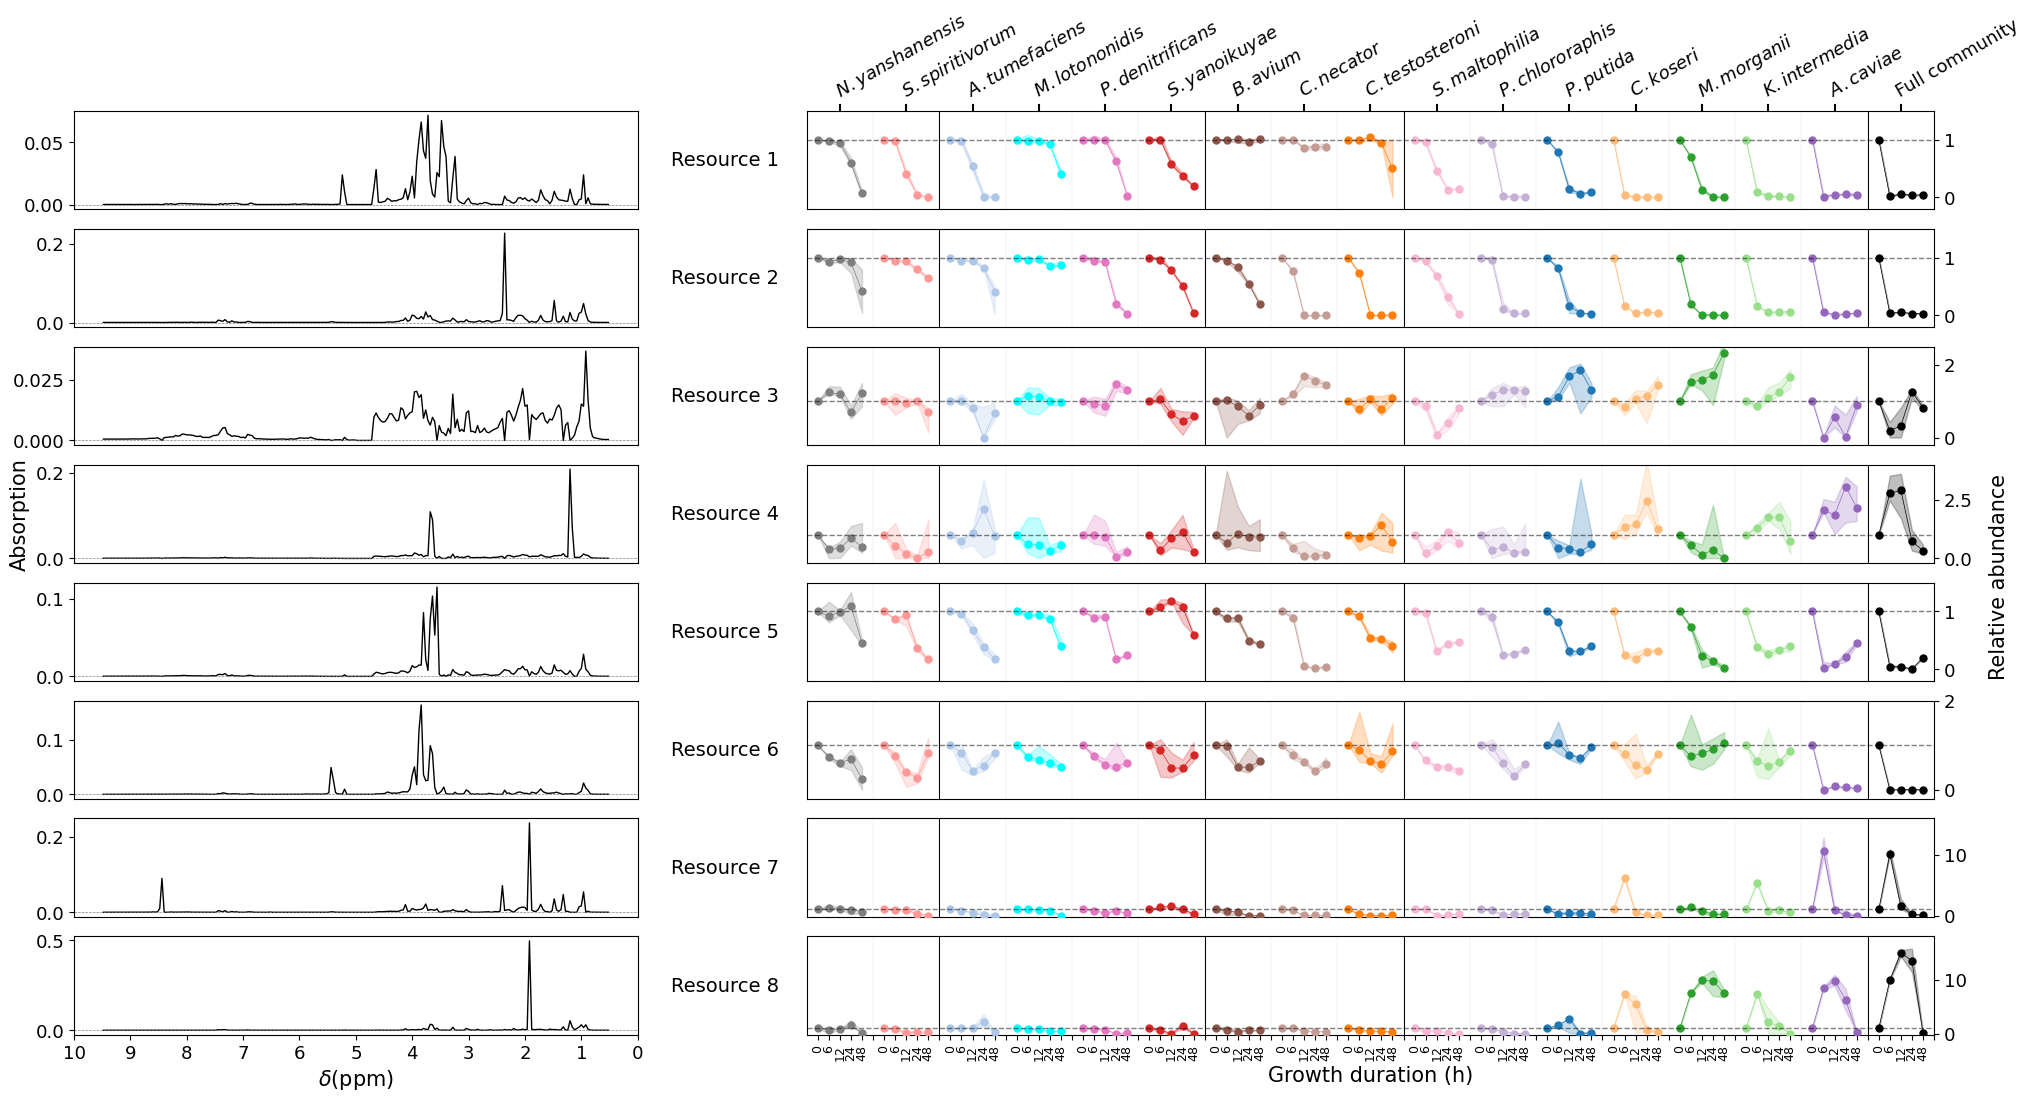

In [2]:
df = ts_nmf_bc_acts.copy()
df["Species"] = [x.split("_")[0] for x in df.index]
df["Replicate"] = [x.split("_")[1] for x in df.index]
df["Time point"] = [x.split("_")[2] for x in df.index]

resource_change_df = pd.DataFrame(columns=["t1", "t2", "t3", "t4"])
for species in df["Species"].unique():
    spec_df = df[df["Species"] == species]
    for replicate in df["Replicate"].unique():
        rep_df = spec_df[spec_df["Replicate"] == replicate]
        for resource_n in range(1, 9):
            resource_change_df.loc[species + "_" + replicate + "_k" + str(resource_n)] = [rep_df[rep_df["Time point"] == tp]["Sig " + str(resource_n)].values[0] for tp in resource_change_df.columns]

order = ["Control"] + list(SPECIES_ORDER) + ["Comm"]

per_resource_ylims = {"1": (-0.2, 1.5), "2": (-0.2, 1.5), "3": (-0.2, 2.5), "4": (-0.2, 4), "5": (-0.2, 1.5), "6": (-0.2, 2), "7": (-0.2, 16), "8": (-0.2, 18)}
species_labels = [r"$\it{" + SPECIES_NAMES_SHORT[x] + "}$" if x != "Comm" else SPECIES_NAMES_SHORT[x] for x in order[1:]]
time_xticks = ["0", "6", "12", "24", "48", ""]*17
resources = [str(i) for i in range(1, 9)]
xmin = -1
xmax = 101

fig = plt.figure(figsize=(12*2, 1.5*8))
grid = GridSpec(8, 2, width_ratios=[1, 2])

# Spectra
spectra_x = ppms
for res in resources:
    ax = fig.add_subplot(grid[int(res)-1, 0])
    
    y = nmr_signatures_8["Sig " + res]
    ylim = (np.min(y)-0.1, np.max(y)+0.1)
    
    ax.plot(spectra_x, y, lw=1, color="black")

    if res == "8":
        ax.set_xlabel(r'$\delta$(ppm)', fontsize=15)
        xticks = np.round(spectra_x, 2)
        ax.set_xticks(range(11), range(11), fontsize=13)
    else:
        ax.set_xticks([], [])

    if res == "4":
        ax.set_ylabel("Absorption", fontsize=15)

    ax.set_xlim(0, 10)
    ax.xaxis.set_inverted(True)
    ax.tick_params(axis="y", labelsize=13)
    plt.hlines(0, plt.xlim()[0], plt.xlim()[1], color="gray", linestyle="dashed", lw=0.5)


# Resources
for res in ["1", "2", "3", "4", "5", "6", "7", "8"]:

    rdf = resource_change_df.loc[[x for x in resource_change_df.index if x.split("_")[2] == "k" + res]]
    ctr = 1

    ax = fig.add_subplot(grid[int(res)-1, 1])
    
    prev_loc = 0
    for sp in order[1:]:
        df = rdf.loc[[x for x in rdf.index if x.split("_")[0] == sp]]
        median_r = df.median(axis=0)
        error_bar_min = np.array([0] + list((df - median_r).min(axis=0).abs().to_numpy()))
        error_bar_max = np.array([0] + list((df - median_r).max(axis=0).abs().to_numpy()))

        y = median_r.to_numpy()
        x = range(prev_loc, prev_loc+len(y)+1)
        y = np.array([ctr] + list(y))

        ax.plot(x, y, color=SPECIES_COLORS[sp], marker='o', zorder=3, lw=0.5, ms=5)
        ax.fill_between(x, y-error_bar_min, y+error_bar_max, color=SPECIES_COLORS[sp], alpha=0.25)
        prev_loc += len(y) + 1
    
    ax.vlines(range(5, 98, 6), per_resource_ylims[res][0], per_resource_ylims[res][1], color="lightgrey", zorder=1, lw=0.2)
    ax.vlines([11, 35, 53, 95], per_resource_ylims[res][0], per_resource_ylims[res][1], color="black", lw=0.75, zorder=2)

    if res == "1":
        xs = np.arange(2, 99, 6)
        i = 0
        for xi in xs:
            ax.text(xi-0.75, 1.75, species_labels[i], rotation=30, ha="left", fontsize=13)
            plt.plot([xi, xi], [per_resource_ylims[res][1], per_resource_ylims[res][1]+0.1], clip_on=False, color="black", lw=1.5)
            i += 1

    ax.tick_params(axis="y", labelsize=13)
    ax.yaxis.tick_right()

    if res == "4":
        plt.text(106, -5, "Relative abundance", rotation=90, fontsize=15)

    if res == "8":
        ax.set_xticks(range(len(time_xticks)), time_xticks, rotation=90, ha="center", va="top", fontsize=9)
        ax.set_xlabel("Growth duration (h)", fontsize=15)
        # plt.text(0.5, -2, "Species", ha="center", va="center", fontsize=15, transform=plt.gca().transAxes)
    else:
        ax.set_xticks([], [])
        
    
    ax.hlines(ctr, xmin, xmax, color="black", linestyle="dashed", lw=1, zorder=4, alpha=0.5)
    
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(per_resource_ylims[res][0], per_resource_ylims[res][1])
    ax.text(-0.025, 0.5, "Resource " + res, ha="right", va="center", fontsize=14, transform=ax.transAxes)
    ax.margins(0.01)

plt.savefig(FIGURES_DIR/"Figure_2a.pdf", bbox_inches="tight")
plt.show()

## Figure 2b

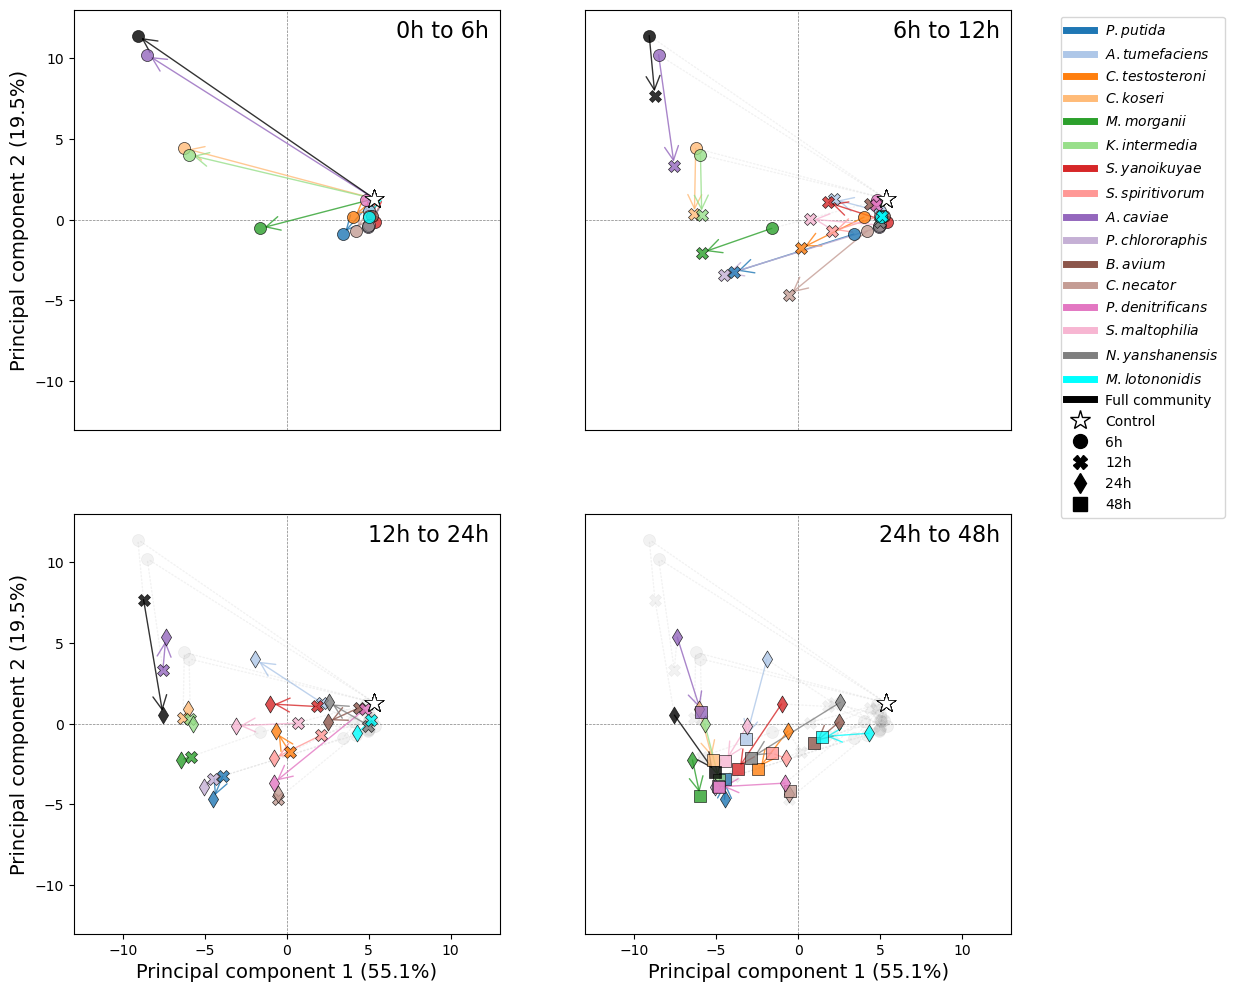

In [3]:
from sklearn.decomposition import PCA

df = ts_nmf_nbc_acts_medians

for sp in SPECIES_LIST_WITH_COMM:
    df.loc[sp + "_m_t0"] = ts_nmf_control_median

pca = PCA(n_components=2).fit(df)
pca_res = pca.fit_transform(df)
exp_var = pca.explained_variance_ratio_
pca_res_df = pd.DataFrame({"PC1": pca_res[:, 0], "PC2": pca_res[:, 1]})
pca_res_df["Time point"] = pd.Series([str(x.split("_")[2]) for x in df.index])
pca_res_df["Species"] = [str(x.split("_")[0]) for x in df.index]

tp_markers = {"t0": "*", "t1": "o", "t2": "X", "t3": "d", "t4": "s"}
tp_labels = {"t0": "Control", "t1": "6h", "t2": "12h", "t3": "24h", "t4": "48h"}
custom_legend = [Line2D([0], [0], lw=5, color=SPECIES_COLORS[species], label='$\it{' + SPECIES_NAMES_SHORT[species] + '}$') for species in SPECIES_LIST.astype(str)] + \
                [Line2D([0], [0], lw=5, color=SPECIES_COLORS["Comm"], label="Full community")] + \
                [Line2D([0], [0], ms=15, lw=0, marker="*", markeredgecolor="black", markerfacecolor="white", label="Control")] + \
                [Line2D([0], [0], ms=10, lw=0, marker=m, color="black", label=tp_labels[tp]) for tp, m in list(tp_markers.items())[1:]]

head_length = 1
head_width = 0.5
arrow_alpha = 0.8
marker_alpha = 0.8
marker_size = 75

disabled_alpha = 0.1
disabled_color="gray"
disabled_alpha_marker = 0.1

arrow_lw = 1

shrinkA = 0
shrinkB = 3

d_multiplier = 0.98

xmin, xmax = (-13, 13)
ymin, ymax = (xmin, xmax)

plot_data = pca_res_df

fig, axs = plt.subplots(2, 2, figsize=(15, 12))

titles = ["0h to 6h", "6h to 12h", "12h to 24h", "24h to 48h"]
si = 1
for tp_pair, tp_set in [(("t0", "t1"), ["t0", "t1"]), (("t1", "t2"), ["t0", "t1", "t2"]), (("t2", "t3"), ["t0", "t1", "t2", "t3"]), (("t3", "t4"), ["t0", "t1", "t2", "t3", "t4"])]:
    ax = plt.subplot(2, 2, si)
    for species in SPECIES_LIST_WITH_COMM:
        scatter_data = plot_data[plot_data["Species"] == species]
        prev_x = None
        prev_y = None
        prev_tp = "t0"
        for tp in tp_set:
            x = list(scatter_data[scatter_data["Time point"] == tp]["PC1"])
            y = list(scatter_data[scatter_data["Time point"] == tp]["PC2"])

            if tp == "t0":
                ax.scatter(x=x, y=y, color="white", marker=tp_markers[tp], edgecolors="black", linewidth=0.5, zorder=10, s=200)
            elif tp in tp_pair:
                ax.scatter(x=x, y=y, color=SPECIES_COLORS[species], marker=tp_markers[tp], edgecolors="black", linewidth=0.5, zorder=10, alpha=marker_alpha, s=marker_size)
            else:
                ax.scatter(x=x, y=y, color=disabled_color, marker=tp_markers[tp], edgecolors=None, linewidth=0.5, zorder=10, alpha=disabled_alpha_marker, s=marker_size)
                
    
            if tp != "t0":
                if tp == tp_pair[1]:
                    for i in range(len(x)):
                        dx = x[i]-prev_x[i]
                        dy = y[i]-prev_y[i]
                        dx *= d_multiplier
                        dy *= d_multiplier
                        if np.abs(dx) > 1 or np.abs(dy) > 1:
                            ax.annotate("", xytext=(prev_x[i], prev_y[i]), xy=(x[i], y[i]),
                                        arrowprops=dict(arrowstyle=f"->, head_length={head_length}, head_width={head_width}", shrinkA=shrinkA, shrinkB=shrinkB, color=SPECIES_COLORS[species], alpha=arrow_alpha, linestyle="solid", lw=arrow_lw, zorder=20))
                        else:
                            ax.annotate("", xytext=(prev_x[i], prev_y[i]), xy=(x[i], y[i]),
                                        arrowprops=dict(arrowstyle=f"-", color=SPECIES_COLORS[species], alpha=arrow_alpha, linestyle="solid", lw=arrow_lw, zorder=20))
                            
                else:
                    for i in range(len(x)):
                        dx = x[i]-prev_x[i]
                        dy = y[i]-prev_y[i]
                        dx *= d_multiplier
                        dy *= d_multiplier
                        ax.annotate("", xytext=(prev_x[i], prev_y[i]), xy=(x[i], y[i]),
                                    arrowprops=dict(arrowstyle=f"-", color=disabled_color, alpha=disabled_alpha, linestyle="dotted", lw=arrow_lw, zorder=1))
                   
    
            prev_x = x
            prev_y = y

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_xlabel(f"Principal component 1 ({np.round(exp_var[0]*100, 1)}%)", fontsize=14)
    ax.set_ylabel(f"Principal component 2 ({np.round(exp_var[1]*100, 1)}%)", fontsize=14)
    ax.text(0.975, 0.975, titles[si-1], transform=ax.transAxes, va="top", ha="right", fontsize=16)
    ax.vlines(0.5, 0, 1, transform=ax.transAxes, color="black", linestyle="dashed", alpha=0.5, lw=0.5, zorder=1)
    ax.hlines(0.5, 0, 1, transform=ax.transAxes, color="black", linestyle="dashed", alpha=0.5, lw=0.5, zorder=1)
    si += 1

axs[0, 0].set_xticks([], [])
axs[0, 0].set_xlabel("")

axs[0, 1].legend(handles=custom_legend, bbox_to_anchor=(1.1, 1))
axs[0, 1].set_xticks([], [])
axs[0, 1].set_xlabel("")
axs[0, 1].set_yticks([], [])
axs[0, 1].set_ylabel("")

axs[1, 1].set_yticks([], [])
axs[1, 1].set_ylabel("")

ax.set_autoscale_on(False)
fig.subplots_adjust(right=0.75)
plt.savefig(FIGURES_DIR/"Figure_2b.pdf", bbox_inches="tight")
plt.show()

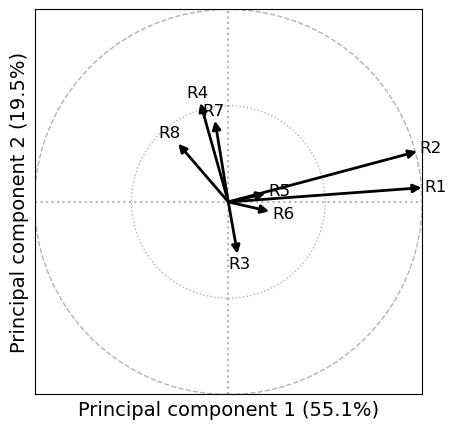

In [4]:
def draw_pca_target(ax, pca,
                    axes, # PCA-axes to plot, e.g. (0,1)
                    featurelabels, # feature names to annotate
                    featurecolors = "k",
                    scatter = None, # datapoints to scatter
                    rays = [3.2/2, 3.2], # datapoints to scatter
                    save_filename = None
                   ):
    """
    Credit: Anthony Sun
    """

    x, y = axes
    ratios = pca.explained_variance_ratio_
    loadings = pca.components_ * np.sqrt(pca.explained_variance_)[:,np.newaxis]
    if isinstance(featurecolors, str): # set up arrow colors
        featurecolors = [featurecolors] * len(featurelabels)

    # draw target
    ax.axhline(0, c="k", alpha=0.3, ls="dotted")
    ax.axvline(0, c="k", alpha=0.3, ls="dotted")
    for r, ray in enumerate(rays):
        circle = plt.Circle((0, 0), ray, color="k", alpha=0.3, ls=["dotted", "dashed"][r], fill=False)
        ax.add_patch(circle)

    if not scatter is None:
        components = pca.fit_transform(scatter)
        ax.scatter(components[:,x], components[:,y])

    for i, feature in enumerate(featurelabels):
        ax.annotate(feature, xy=(0,0), xytext=(loadings[x,i], loadings[y,i]), fontsize=12,
            arrowprops={"arrowstyle":"<|-", "color": featurecolors[i], "shrinkA": 0, "shrinkB": 0, "lw": 2})
    
    ax.set_xlim(-3.2, 3.2)
    ax.set_ylim(-3.2, 3.2)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel(f"Principal component 1 ({np.round(ratios[0]*100, 1)}%)", fontsize=14)
    ax.set_ylabel(f"Principal component 2 ({np.round(ratios[1]*100, 1)}%)", fontsize=14)
    if save_filename:
        plt.savefig(save_filename, bbox_inches="tight")
    
    return loadings, ratios

fig, ax = plt.subplots(figsize=(5, 5))
_ = draw_pca_target(ax, pca, (0, 1), ["R" + str(i) for i in range(1, 9)], save_filename=FIGURES_DIR/"Figure_2b_loadings.pdf")
plt.show()

# Figure 3 and Table S1

## Figure 3

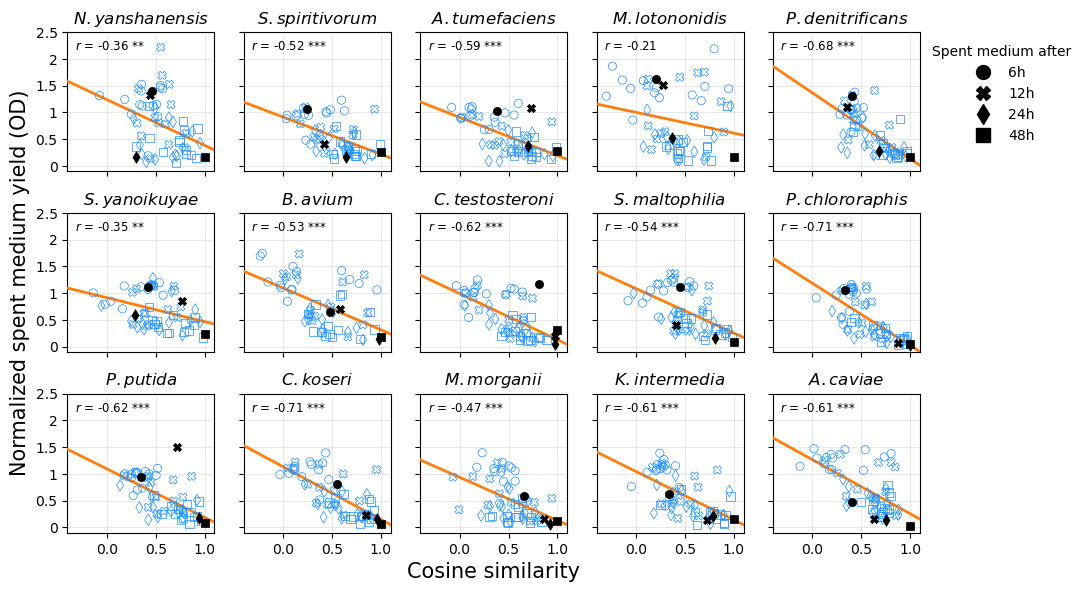

In [5]:
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.linear_model import LinearRegression
from scipy import stats

cosims = pd.DataFrame(columns=["Similarity"])
for sp1 in SPECIES_LIST.astype(str):
    for sp2 in SPECIES_LIST.astype(str):
        for tp in ["t1", "t2", "t3", "t4"]:
            I_1 = np.log(ts_nmf_nbc_acts_medians.loc[f"{sp1}_m_{tp}"] + PSEUDOCOUNT) - np.log(ts_nmf_control_median + PSEUDOCOUNT)
            I_2 = np.log(ts_nmf_nbc_acts_medians.loc[f"{sp2}_m_t4"] + PSEUDOCOUNT) - np.log(ts_nmf_control_median + PSEUDOCOUNT)
            cosims.loc[f"{sp1}_{sp2}_{tp}"] = cosine_similarity(I_1.to_numpy().reshape(1, -1), I_2.to_numpy().reshape(1, -1))[0][0]

tp_markers = {"t0": "*", "t1": "o", "t2": "X", "t3": "d", "t4": "s"}
tp_labels = {"t0": "Control", "t1": "6h", "t2": "12h", "t3": "24h", "t4": "48h"}
custom_legend = [Line2D([0], [0], ms=10, lw=0, marker=m, color="black", label=tp_labels[tp]) for tp, m in list(tp_markers.items())[1:]]
xlim = (np.min(cosims.to_numpy())-0.1, np.max(cosims.to_numpy())+0.1)
ylim = (-0.1, 2.5)

testing_results = pd.DataFrame(columns=["Slope", "CI low", "CI high", "DF", "t", "p", "r", "n"])

si = 1
plt.subplots(3, 5, figsize=(11, 6.5))
for sp1 in SPECIES_ORDER_WO_2164:
    plt.subplot(3, 5, si)
    mono_yield = mono_and_pair_stats_and_params[(mono_and_pair_stats_and_params["Culture"] == "Monoculture") & (mono_and_pair_stats_and_params["Species"] == sp1)]["Yield"].median() - 0.1
    y = []
    x = []
    for sp2 in SPECIES_ORDER_WO_2164:
        for tp in ["t1", "t2", "t3", "t4"]:
            cs = cosims.loc[f"{sp2}_{sp1}_{tp}"].values[0]
            yld = (filtrate_growth_curves.loc[f"{sp2}_{sp1}_{tp}"].iloc[-1] - 0.1)/mono_yield
            y.append(yld)
            x.append(cs)
            
            if sp1 != sp2:
                plt.scatter(cs, yld, edgecolor="dodgerblue", facecolors="none", marker=tp_markers[tp], label=sp2, zorder=10, alpha=1, s=35, lw=0.5)
            else:
                plt.scatter(cs, yld, edgecolor="black", facecolors="black", marker=tp_markers[tp], label=sp2, zorder=15, alpha=1, s=35, lw=0.5)
                
    
    y = np.array(y).astype(float).reshape(-1, 1)
    x = np.array(x).astype(float).reshape(-1, 1)
    reg = LinearRegression().fit(x, y)
    x_fit = np.arange(xlim[0], xlim[1]+0.02, 0.01)
    y_fit = (reg.coef_*x_fit + reg.intercept_).reshape(-1, 1)
    plt.plot(x_fit, y_fit, color="tab:orange", alpha=1, lw=2, linestyle="solid", zorder=5)

    res = stats.linregress(np.asarray(x, dtype=float).ravel(), np.asarray(y, dtype=float).ravel())
    n = len(x)
    deg_f = n - 2
    t_stat = res.slope/res.stderr
    t_crit = stats.t.ppf(0.975, deg_f)
    ci = (res.slope - t_crit*res.stderr, res.slope + t_crit*res.stderr)
    p_value = res.pvalue

    testing_results.loc[sp1, "Slope"] = res.slope
    testing_results.loc[sp1, "CI low"] = ci[0]
    testing_results.loc[sp1, "CI high"] = ci[1]
    testing_results.loc[sp1, "DF"] = deg_f
    testing_results.loc[sp1, "t"] = t_stat
    testing_results.loc[sp1, "p"] = p_value
    testing_results.loc[sp1, "r"] = res.rvalue
    testing_results.loc[sp1, "n"] = n
    
    corrcoef = np.round(np.corrcoef(x.flatten(), y.flatten())[0, 1], 2)
    if corrcoef > 0:
        corrcoef_string = str(corrcoef)
    else:
        corrcoef_string = str(corrcoef)

    if p_value < 0.001:
        corrcoef_string += " ***"
    elif p_value < 0.01:
        corrcoef_string += " **"
    elif p_value < 0.05:
        corrcoef_string += " *"
    
    plt.text(0.05, 0.85, f"$r$ = {corrcoef_string}", transform=plt.gca().transAxes, ha="left", va="bottom", fontsize=8.5, color="black")
    plt.title("$\it{" + SPECIES_NAMES_SHORT[sp1] + "}$")
    plt.xlim(xlim)
    plt.ylim(ylim)

    if si == 6:
        plt.ylabel("Normalized spent medium yield (OD)", fontsize=15)

    yticks = [0, 0.5, 1, 1.5, 2, 2.5]
    xticks = [0.0, 0.5, 1.0]
    if not si in [1, 6, 11]:
        plt.yticks(yticks, [""]*len(yticks))
    else:
        plt.yticks(yticks, yticks)

    if not si in [11, 12, 13, 14, 15]:
        plt.xticks(xticks, [""]*len(xticks))
    else:
        plt.xticks(xticks, xticks)
    
    if si == 13:
        plt.xlabel("Cosine similarity", fontsize=15)  

    plt.hlines(yticks, xlim[0], xlim[1], color="lightgray", alpha=0.5, lw=0.75)
    plt.vlines(xticks, ylim[0], ylim[1], color="lightgray", alpha=0.5, lw=0.75)
    si += 1

testing_results.index = [SPECIES_NAMES_SHORT[x] for x in testing_results.index]

plt.subplot(3, 5, 5)
plt.legend(handles=custom_legend, title="Spent medium after", bbox_to_anchor=(1, 1), frameon=False)
plt.subplots_adjust(hspace=0.3)
plt.savefig(FIGURES_DIR/"Figure_3.pdf", bbox_inches="tight")
plt.show()

## Table S1

In [6]:
testing_results

,Slope,CI low,CI high,DF,t,p,r,n
N. yanshanensis,-0.855251,-1.433609,-0.276894,58,-2.960058,0.004449,-0.362273,60
S. spiritivorum,-0.693989,-0.994845,-0.393133,58,-4.617394,0.000022,-0.518447,60
A. tumefaciens,-0.715218,-0.973674,-0.456763,58,-5.539308,0.000001,-0.588211,60
M. lotononidis,-0.387502,-0.871744,0.096739,58,-1.601824,0.114627,-0.205826,60
P. denitrificans,-1.232085,-1.58042,-0.88375,58,-7.08021,0.0,-0.680886,60
S. yanoikuyae,-0.448002,-0.762406,-0.133597,58,-2.852291,0.006005,-0.350733,60
B. avium,-0.78187,-1.108429,-0.45531,58,-4.792638,0.000012,-0.532616,60
C. testosteroni,-0.86149,-1.146816,-0.576164,58,-6.043817,0.0,-0.62163,60
S. maltophilia,-0.829958,-1.169896,-0.49002,58,-4.887193,0.000008,-0.54008,60
P. chlororaphis,-1.161731,-1.464266,-0.859195,58,-7.686554,0.0,-0.71037,60


# Figure 4

In [7]:
from sklearn.linear_model import LinearRegression

ts_nmf_impact_medians_monos = ts_nmf_impact_medians.loc[[x for x in ts_nmf_impact_medians.index if not "+" in x and not "Comm" in x]]
ts_nmf_impact_medians_monos.index = [x.split("_")[0] + "_" + x.split("_")[2] for x in ts_nmf_impact_medians_monos.index]
impact_vectors = ts_nmf_impact_medians_monos.drop(["2164_t1", "2164_t2", "2164_t3", "2164_t4"])
impact_vectors.index = impact_vectors.index.astype(str)
impact_vectors = np.exp(impact_vectors)  # Non-log data, without division by dNdt; that's done in a later step below

# These yields are base-corrected after reading in the data
filtrate_yields = {"t1": flt_1.copy(), "t2": flt_2.copy(), "t3": flt_3.copy(), "t4": flt_4.copy()}
for t in filtrate_yields.keys():
    filtrate_yields[t].index = filtrate_yields[t].index.astype(str)
    filtrate_yields[t].columns = filtrate_yields[t].columns.astype(str)

predictors = pd.DataFrame(index=[x + "_" + z for x in SPECIES_LIST_WO_2164 for z in ["t1", "t2", "t3", "t4"]], columns=impact_vectors.columns)
responses = pd.DataFrame(index=predictors.index, columns=SPECIES_LIST_WO_2164)

predictors_mono = pd.DataFrame(index=[x + "_mono" for x in SPECIES_LIST_WO_2164], columns=impact_vectors.columns)
responses_mono = pd.DataFrame(index=[x + "_mono" for x in SPECIES_LIST_WO_2164], columns=["y"])

for sp1 in SPECIES_LIST_WO_2164:
    predictors_mono.loc[sp1 + "_mono", impact_vectors.columns] = ts_nmf_control_median/ts_nmf_control_median
    responses_mono.loc[sp1 + "_mono", "y"] = monogrowth_medians_df.loc[int(sp1)].iloc[-1] - 0.1
    
    for t in ["t1", "t2", "t3", "t4"]:
        predictors.loc[sp1 + "_" + t, impact_vectors.columns] = impact_vectors.loc[sp1 + "_" + t]
        for sp2 in SPECIES_LIST_WO_2164:
            responses.loc[sp1 + "_" + t, sp2] = filtrate_yields[t].loc[sp1, sp2]


pseudo_nu = np.log((ts_nmf_nbc_acts_medians + PSEUDOCOUNT)/(ts_nmf_control_median + PSEUDOCOUNT))
pseudo_nu.index = [x.split("_")[0] + "_" + x.split("_")[2] for x in pseudo_nu.index]
pseudo_nu = pseudo_nu.loc[[x for x in pseudo_nu.index if x.split("_")[1] == "t4"]]
pseudo_nu.index = [x.split("_")[0] for x in pseudo_nu.index]

scores = {}
scatter_x = []
scatter_y = []

nus_scatter = []
rs_scatter = []

yield_cofs = []
Nu = []

for sp in SPECIES_ORDER_WO_2164:
    sp_responses = responses.loc[:, sp].copy()
    sp_predictors = predictors.copy()

    nu = pseudo_nu.loc[sp]/(-monogrowth_medians_df.loc[int(sp)].iloc[-1] - 0.1)  # Actual impact vector
    
    for t in ["t1", "t2", "t3", "t4"]:
        for sp_prime in SPECIES_ORDER_WO_2164:
            sp_predictors.loc[sp_prime + "_" + t] = sp_predictors.loc[sp_prime + "_" + t]

    sp_predictors.loc[sp + "_mono"] = predictors_mono.loc[sp + "_mono"]
    sp_responses.loc[sp + "_mono"] = responses_mono.loc[sp + "_mono", "y"]
    
    model = LinearRegression(positive=False)
    model.fit(sp_predictors, sp_responses)
    
    weights = model.coef_
    intercept = model.intercept_

    yield_cofs.append(weights)
    scores[sp] = model.score(sp_predictors, sp_responses)
    scatter_x.append(sp_responses)
    scatter_y.append(model.predict(sp_predictors))

    nus_scatter += list(nu)
    rs_scatter += list(weights)

    Nu.append(nu)

yield_cofs = np.array(yield_cofs)
Nu = np.array(Nu)
r = yield_cofs*Nu

## Figure 4a

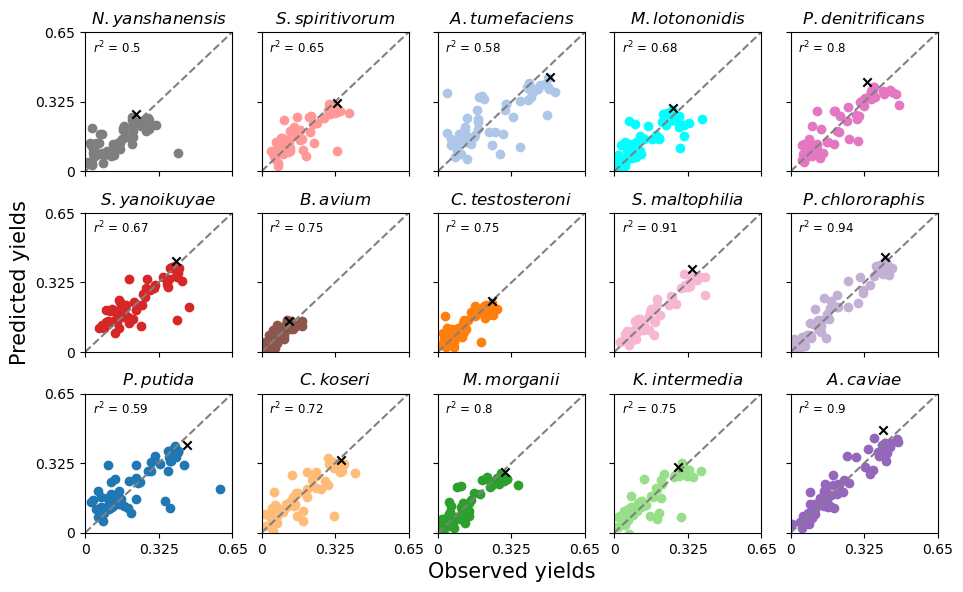

In [8]:
from scipy import stats

plt.subplots(3, 5, figsize=(11, 6.5))
si = 1
for i in range(len(SPECIES_ORDER_WO_2164)):
    
    plt.subplot(3, 5, si)
    plt.scatter(scatter_x[i].iloc[:-1], scatter_y[i][:-1], color=SPECIES_COLORS[SPECIES_ORDER_WO_2164[i]])
    plt.scatter(scatter_x[i].iloc[-1], scatter_y[i][-1], color="black", marker="x", zorder=10)
    plt.plot([0, 1], [0, 1], linestyle="dashed", color="grey", transform=plt.gca().transAxes)
    plt.title("$\it{" + SPECIES_NAMES_SHORT[SPECIES_ORDER_WO_2164[i]] + "}$")

    slope, intercept, r_value, p_value, std_err = stats.linregress(scatter_x[i].to_numpy().astype(float), scatter_y[i].reshape(-1, 1).flatten())

    corrcoef = np.round(scores[SPECIES_ORDER_WO_2164[i]], 2)
    corrcoef_string = str(corrcoef)
        
    plt.text(0.05, 0.95, f"$r^2$ = {corrcoef_string}", transform=plt.gca().transAxes, va="top", ha="left", fontsize=8.5, color="black")

    plt.xlim(0, 0.65)
    plt.ylim(0, 0.65)

    if not si in [1, 6, 11]:
        plt.yticks([0, 0.325, 0.65], ["", "", ""])
    else:
        plt.yticks([0, 0.325, 0.65], [0, 0.325, 0.65])

    if not si in [11, 12, 13, 14, 15]:
        plt.xticks([0, 0.325, 0.65], ["", "", ""])
    else:
        plt.xticks([0, 0.325, 0.65], [0, 0.325, 0.65])

    if si == 13:
        plt.xlabel("Observed yields", fontsize=15)

    if si == 6:
        plt.ylabel("Predicted yields", rotation=90, fontsize=15)

    si += 1

plt.subplots_adjust(hspace=0.3)
plt.savefig(FIGURES_DIR/"Figure_4a.pdf", bbox_inches="tight")
plt.show()

## Figure 4b

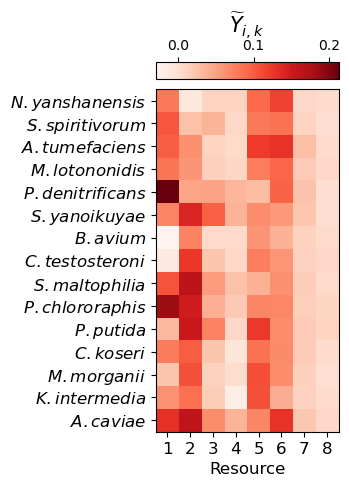

In [9]:
from matplotlib.ticker import FormatStrFormatter
from mpl_toolkits.axes_grid1 import make_axes_locatable

plt.figure()
plt.imshow(yield_cofs, cmap="Reds")
plt.yticks(range(len(SPECIES_ORDER_WO_2164)), [r"$\it{" + SPECIES_NAMES_SHORT[x] + "}$" for x in SPECIES_ORDER_WO_2164], fontsize=12)
plt.xticks(range(len(predictors.columns)), [str(i) for i in range(1, 9)], rotation=0, fontsize=12)
plt.xlabel("Resource", fontsize=12)

divider = make_axes_locatable(plt.gca())
cax = divider.append_axes("top", size="5%", pad=0.1)
cbar = plt.colorbar(cax=cax, orientation="horizontal")
cax.xaxis.set_ticks_position("top") 
cax.xaxis.set_label_position("top")
cbar.set_label(r"$\widetilde{Y}_{i,k}$", fontsize=15)
cbar.ax.tick_params(labelsize=10)

plt.savefig(FIGURES_DIR/"Figure_4b.pdf", bbox_inches="tight")
plt.show()

## Figure 4c

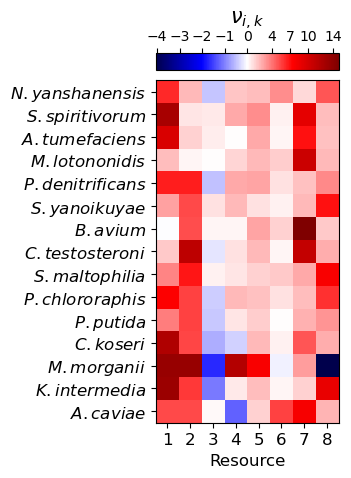

In [10]:
from matplotlib.ticker import FormatStrFormatter
from mpl_toolkits.axes_grid1 import make_axes_locatable

plt.figure()
plt.imshow(Nu, cmap="seismic", norm=TwoSlopeNorm(vmin=np.min(Nu), vcenter=0, vmax=np.max(Nu)))
plt.yticks(range(len(SPECIES_ORDER_WO_2164)), [r"$\it{" + SPECIES_NAMES_SHORT[x] + "}$" for x in SPECIES_ORDER_WO_2164], fontsize=12)
plt.xticks(range(len(predictors.columns)), [str(i) for i in range(1, 9)], rotation=0, fontsize=12)
plt.xlabel("Resource", fontsize=12)

divider = make_axes_locatable(plt.gca())
cax = divider.append_axes("top", size="5%", pad=0.1)
cbar = plt.colorbar(cax=cax, orientation="horizontal")
cax.xaxis.set_ticks_position("top") 
cax.xaxis.set_label_position("top")
cbar.set_label(r"$\nu_{i,k}$", fontsize=15)

# More ticks
lo = np.ceil(np.min(Nu))
hi = np.floor(np.max(Nu))
ticks = np.concatenate([
    np.linspace(lo, 0, 5)[:-1],
    np.linspace(0, hi, 5),
])
ticks = np.unique(np.round(ticks))

cbar.set_ticks(ticks)
cbar.ax.tick_params(labelsize=10)
cbar.ax.yaxis.set_major_formatter(FormatStrFormatter("%.2g"))
plt.savefig(FIGURES_DIR/"Figure_4c.pdf", bbox_inches="tight")
plt.show()

## Figure 4d

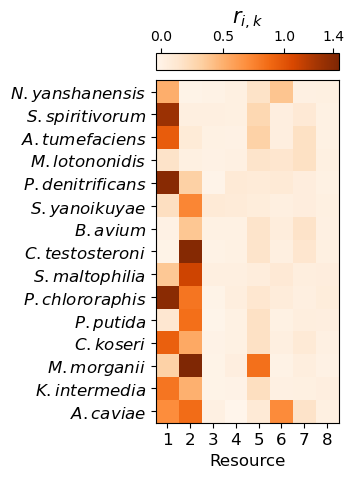

In [11]:
from matplotlib.ticker import FormatStrFormatter
from mpl_toolkits.axes_grid1 import make_axes_locatable

plt.figure()
plt.imshow(r, cmap="Oranges")
plt.yticks(range(len(SPECIES_ORDER_WO_2164)), [r"$\it{" + SPECIES_NAMES_SHORT[x] + "}$" for x in SPECIES_ORDER_WO_2164], fontsize=12)
plt.xticks(range(len(predictors.columns)), [str(i) for i in range(1, 9)], rotation=0, fontsize=12)
plt.xlabel("Resource", fontsize=12)

divider = make_axes_locatable(plt.gca())
cax = divider.append_axes("top", size="5%", pad=0.1)
cbar = plt.colorbar(cax=cax, orientation="horizontal")
cbar.set_ticks([0, 0.5, 1.0, 1.4])
cax.xaxis.set_ticks_position("top") 
cax.xaxis.set_label_position("top")
cbar.set_label(r"$r_{i,k}$", fontsize=15)
cbar.ax.tick_params(labelsize=10)
plt.savefig(FIGURES_DIR/"Figure_4d.pdf", bbox_inches="tight")
plt.show()

# Figure 5

## Figure 5a

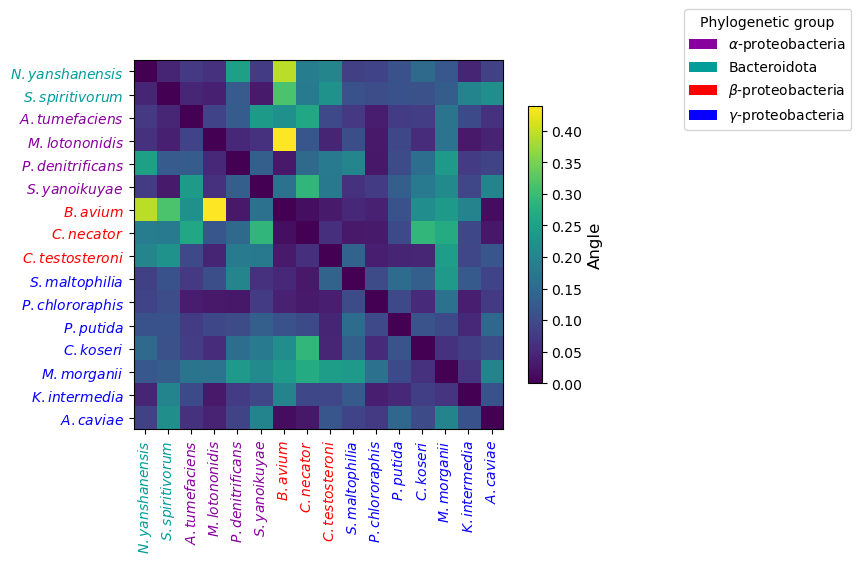

In [12]:
df = interp_nu_df

min_angles = pd.DataFrame(index=SPECIES_LIST.astype(str), columns=SPECIES_LIST.astype(str))

for i in range(len(SPECIES_LIST)-1):
    sp1 = str(SPECIES_LIST[i])
    for j in range(i+1, len(SPECIES_LIST)):
        sp2 = str(SPECIES_LIST[j])

        sp1_df = df.loc[[x for x in df.index if x.split("_")[0] == sp1]].iloc[:, :8]
        sp2_df = df.loc[[x for x in df.index if x.split("_")[0] == sp2]].iloc[:, :8]
        bi_df = df.loc[[x for x in df.index if x.split("_")[0] == sp1 + "+" + sp2]].iloc[:, :8]
        
        angles = []
        for idx_1 in sp1_df.index:
            for idx_2 in sp2_df.index:
                for bi_idx in bi_df.index:
                    a = sp1_df.loc[idx_1].to_numpy().flatten().astype(float)
                    b = sp2_df.loc[idx_2].to_numpy().flatten().astype(float)
                    c = bi_df.loc[bi_idx].to_numpy().flatten().astype(float)
                    angles.append(gram_angle(a, b, c))

        min_angle = np.min(angles)
        min_angles.loc[sp1, sp2] = min_angle
        min_angles.loc[sp2, sp1] = min_angle
        min_angles.loc[sp1, sp1] = 0
        min_angles.loc[sp2, sp2] = 0

min_angle_df = pd.DataFrame(columns=["Angle"])
for i in range(len(SPECIES_LIST)-1):
    sp1 = str(SPECIES_LIST[i])
    for j in range(i, len(SPECIES_LIST)):
        sp2 = str(SPECIES_LIST[j])
        min_angle_df.loc[f"{sp1}+{sp2}"] = min_angles.loc[sp1, sp2]

min_angles = min_angles.loc[SPECIES_ORDER, SPECIES_ORDER]

plt.figure()

phylo_labels = pd.Series([PHYLO_GROUPS_FANCY[str(x)] for x in SPECIES_ORDER])
cluster_phylo_colors = phylo_labels.map(PHYLO_COLORS_FANCY)
handles = [Patch(facecolor=PHYLO_COLORS_FANCY[name]) for name in PHYLO_COLORS_FANCY]

x_labels = ["$\it{" + SPECIES_NAMES_SHORT[x] + "}$" for x in SPECIES_ORDER]
y_labels = ["$\it{" + SPECIES_NAMES_SHORT[x] + "}$" for x in SPECIES_ORDER]

plt.imshow(min_angles.to_numpy().astype(float), cmap="viridis")
plt.xticks(range(len(x_labels)), x_labels, rotation=90)
plt.yticks(range(len(y_labels)), y_labels)

for i in range(len(x_labels)):
    plt.gca().get_xticklabels()[i].set_color(PHYLO_COLORS_FANCY[PHYLO_GROUPS_FANCY[SPECIES_ORDER[i]]]) 
    plt.gca().get_yticklabels()[i].set_color(PHYLO_COLORS_FANCY[PHYLO_GROUPS_FANCY[SPECIES_ORDER[i]]]) 

cbar = plt.colorbar(shrink=0.75)
cbar.set_label("Angle", fontsize=12)

plt.legend(handles, PHYLO_COLORS_FANCY, title="Phylogenetic group", bbox_to_anchor=(1.3, 1), bbox_transform=plt.gcf().transFigure, loc='upper right')

plt.savefig(FIGURES_DIR/"Figure_5a.pdf", bbox_inches="tight")
plt.show()

## Figure 5b

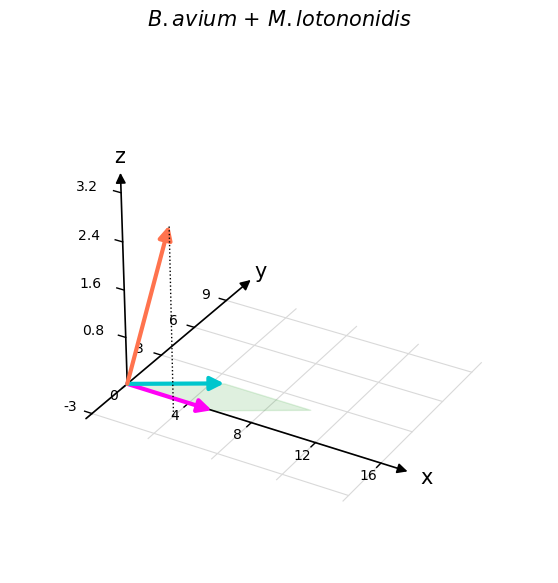

In [13]:
sp1 = "2160"
sp2 = "3237"

title = "$\\it{" + SPECIES_NAMES_SHORT[sp1] + "}$ + $\\it{" + SPECIES_NAMES_SHORT[sp2] + "}$"
data_df = np.log(ep_nmf_nbc_acts_medians.loc[[sp1 + "_m_ep", sp2 + "_m_ep", sp1 + "+" + sp2 + "_m_ep"]] + PSEUDOCOUNT) - np.log(ep_nmf_control_median + PSEUDOCOUNT)
plot_3d(data_df, sp1, sp2, title, xmax=16, ymax=10, ymin=-3.5, zmax=3.2, save_filename=FIGURES_DIR/"Figure_5b_1.pdf")

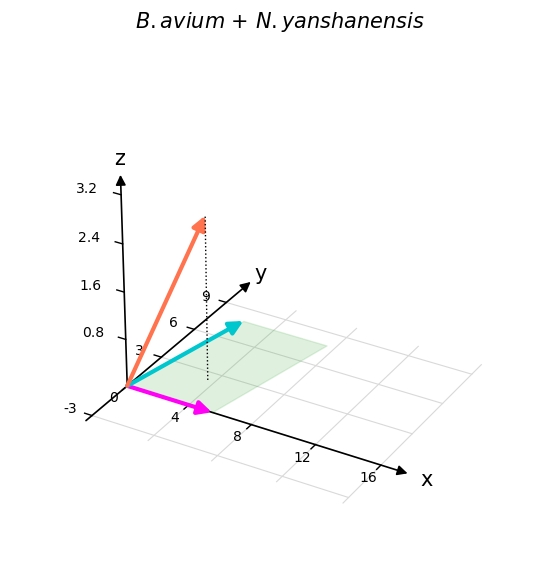

In [14]:
sp1 = "2160"
sp2 = "3031"

title = "$\\it{" + SPECIES_NAMES_SHORT[sp1] + "}$ + $\\it{" + SPECIES_NAMES_SHORT[sp2] + "}$"
data_df = np.log(ep_nmf_nbc_acts_medians.loc[[sp1 + "_m_ep", sp2 + "_m_ep", sp1 + "+" + sp2 + "_m_ep"]] + PSEUDOCOUNT) - np.log(ep_nmf_control_median + PSEUDOCOUNT)
plot_3d(data_df, sp1, sp2, title, xmax=16, ymax=10, ymin=-3.5, zmax=3.2, save_filename=FIGURES_DIR/"Figure_5b_2.pdf")

## Figure 5c

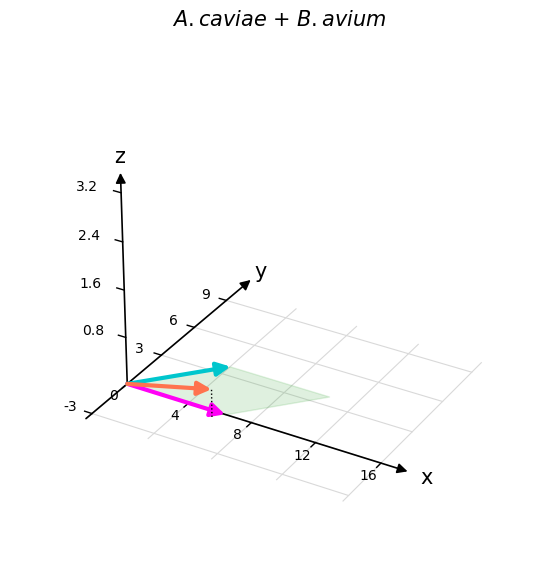

In [15]:
sp1 = "1972"
sp2 = "2160"

title = "$\\it{" + SPECIES_NAMES_SHORT[sp1] + "}$ + $\\it{" + SPECIES_NAMES_SHORT[sp2] + "}$"
data_df = np.log(ep_nmf_nbc_acts_medians.loc[[sp1 + "_m_ep", sp2 + "_m_ep", sp1 + "+" + sp2 + "_m_ep"]] + PSEUDOCOUNT) - np.log(ep_nmf_control_median + PSEUDOCOUNT)
plot_3d(data_df, sp1, sp2, title, xmax=16, ymax=10, ymin=-3.5, zmax=3.2, save_filename=FIGURES_DIR/"Figure_5c_1.pdf")

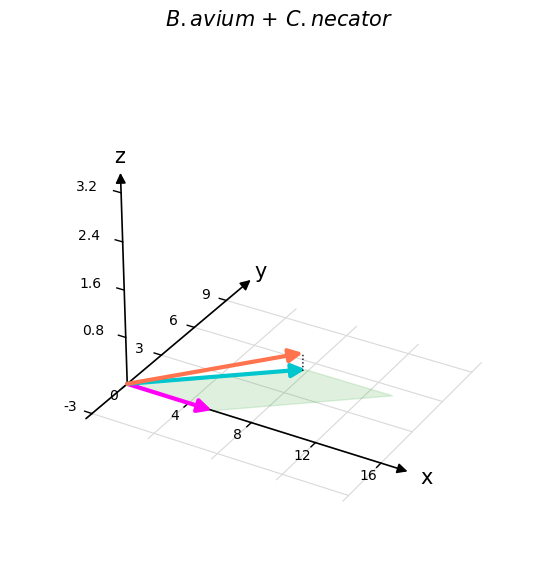

In [16]:
sp1 = "2160"
sp2 = "2164"

title = "$\\it{" + SPECIES_NAMES_SHORT[sp1] + "}$ + $\\it{" + SPECIES_NAMES_SHORT[sp2] + "}$"
data_df = np.log(ep_nmf_nbc_acts_medians.loc[[sp1 + "_m_ep", sp2 + "_m_ep", sp1 + "+" + sp2 + "_m_ep"]] + PSEUDOCOUNT) - np.log(ep_nmf_control_median + PSEUDOCOUNT)
plot_3d(data_df, sp1, sp2, title, xmax=16, ymax=10, ymin=-3.5, zmax=3.2, save_filename=FIGURES_DIR/"Figure_5c_2.pdf")

# Figure S3

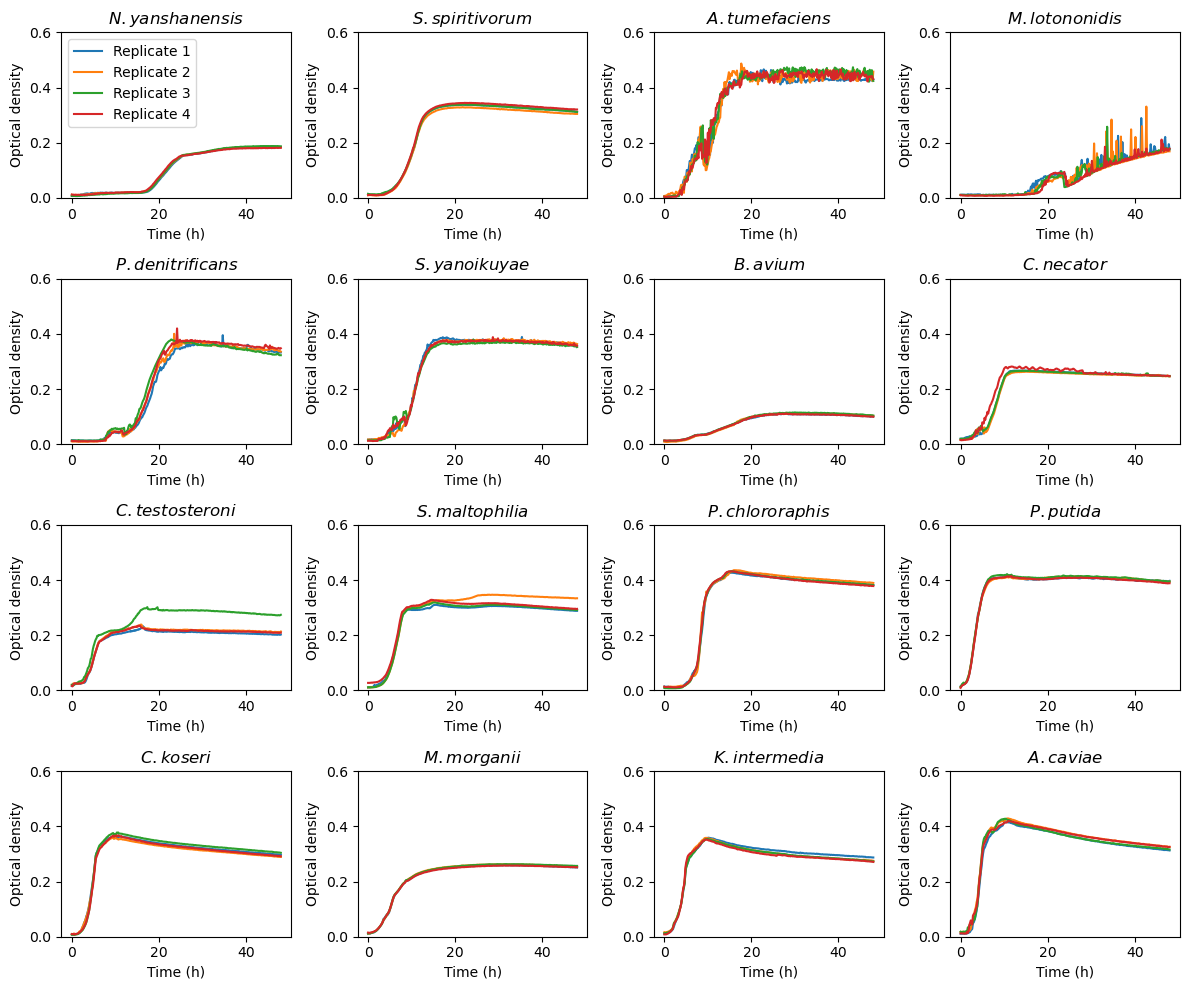

In [17]:
plt.subplots(4, 4, figsize=(12, 10))
si = 1
for species in SPECIES_ORDER:
    plt.subplot(4, 4, si)
    curves = mono_median_curves.loc[[x for x in mono_median_curves.index if x.split("_")[0] == species]]
    for i in range(len(curves)):
        curve = curves.iloc[i] - 0.1
        time = [x*10/60 for x in range(len(curve))]
        plt.plot(time, curve, label="Replicate " + str(i+1))
    plt.xlabel("Time (h)")
    plt.ylabel("Optical density")
    plt.title(r"$\it{" + SPECIES_NAMES_SHORT[str(species)] + "}$")
    plt.ylim(0, 0.6)
    if species == "3031":
        plt.legend(loc="upper left")
    si += 1
plt.tight_layout()
plt.savefig(FIGURES_DIR/"Figure_S3.pdf", bbox_inches="tight")
plt.show()

# Figure S2

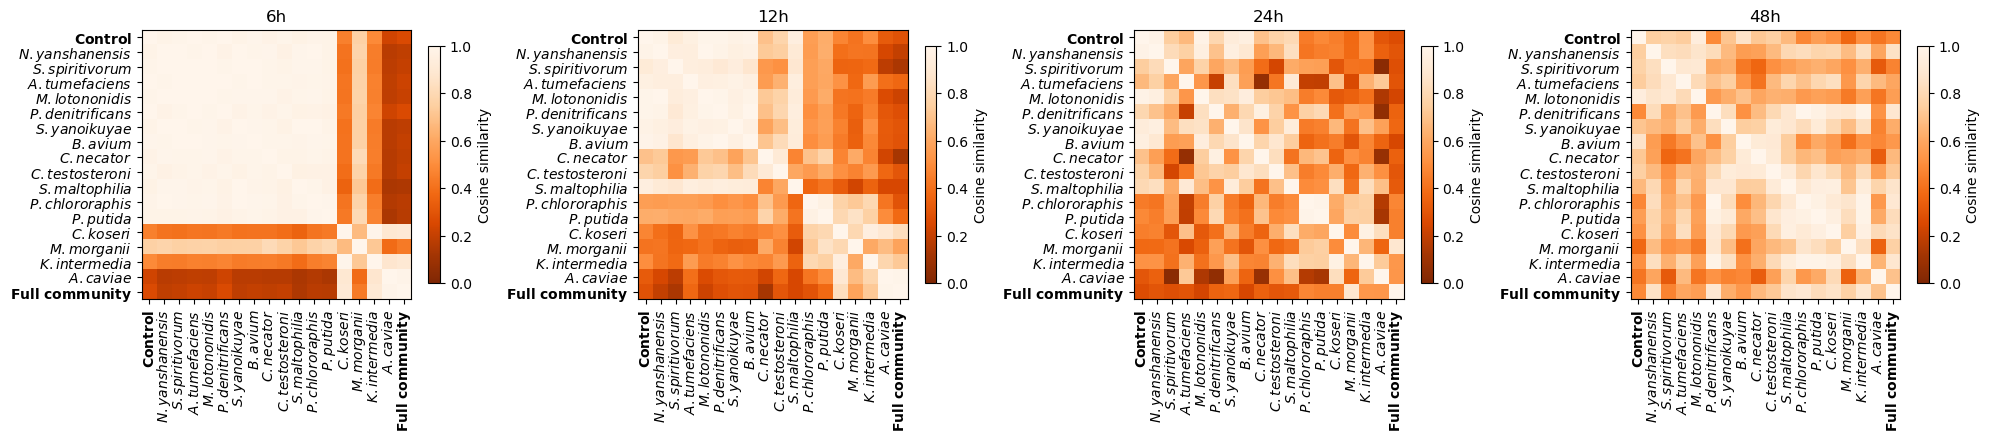

In [18]:
from sklearn.metrics.pairwise import cosine_similarity

dummy_control_df = pd.concat([ts_nmf_control_median, ts_nmf_control_median, ts_nmf_control_median, ts_nmf_control_median], axis=1).T
dummy_control_df.index = ["Control_m_t1", "Control_m_t2", "Control_m_t3", "Control_m_t4"]

df = pd.concat([ts_nmf_mono_nbc_acts_medians, ts_nmf_comm_nbc_acts_medians, dummy_control_df])
time_profiles = pd.DataFrame(columns=(["T1 " + df.columns[i] for i in range(len(df.columns))] + ["T2 " + df.columns[i] for i in range(len(df.columns))] + ["T3 " + df.columns[i] for i in range(len(df.columns))] + ["T4 " + df.columns[i] for i in range(len(df.columns))]))
for species in list(SPECIES_LIST.astype(str)) + ["Comm", "Control"]:
    sp_idx = [x for x in df.index if x.split("_")[0] == species]
    assert len(sp_idx) == 4
    time_profiles.loc[species] = np.array(pd.concat([df.loc[sp_idx[0]], df.loc[sp_idx[1]], df.loc[sp_idx[2]], df.loc[sp_idx[3]]]))

order = ["Control"] + list(SPECIES_ORDER) + ["Comm"]
order_species_names = ['$\mathbf{Control}$'] + ['$\it{' + SPECIES_NAMES_SHORT[x] + '}$' for x in order[1:-1]] + ['$\mathbf{Full\ community}$']
time_profiles = time_profiles.loc[order]

t1_profile = time_profiles.loc[:, [x for x in time_profiles.columns if x.split()[0] == "T1"]]
t2_profile = time_profiles.loc[:, [x for x in time_profiles.columns if x.split()[0] == "T2"]]
t3_profile = time_profiles.loc[:, [x for x in time_profiles.columns if x.split()[0] == "T3"]]
t4_profile = time_profiles.loc[:, [x for x in time_profiles.columns if x.split()[0] == "T4"]]

t1_profile.index = [SPECIES_NAMES_SHORT[x] for x in t1_profile.index]
t2_profile.index = [SPECIES_NAMES_SHORT[x] for x in t2_profile.index]
t3_profile.index = [SPECIES_NAMES_SHORT[x] for x in t3_profile.index]
t4_profile.index = [SPECIES_NAMES_SHORT[x] for x in t4_profile.index]

csm1 = cosine_similarity(t1_profile)
csm2 = cosine_similarity(t2_profile)
csm3 = cosine_similarity(t3_profile)
csm4 = cosine_similarity(t4_profile)

vmin = np.min([np.min(csm1), np.min(csm2), np.min(csm3), np.min(csm4)])
vmax = np.max([np.max(csm1), np.max(csm2), np.max(csm3), np.max(csm4)])

vmin = 0
vmax = 1

cmap = "Oranges_r"

plt.subplots(1, 4, figsize=(20, 5))
plt.subplot(1, 4, 1)
plt.imshow(csm1, vmin=vmin, vmax=vmax, cmap=cmap)
plt.xticks(range(len(t1_profile.index)), order_species_names, rotation=90)
plt.yticks(range(len(t1_profile.index)), order_species_names)
plt.title("6h")
plt.colorbar(shrink=0.6, label="Cosine similarity")

plt.subplot(1, 4, 2)
plt.imshow(csm2, vmin=vmin, vmax=vmax, cmap=cmap)
plt.xticks(range(len(t1_profile.index)), order_species_names, rotation=90)
plt.yticks(range(len(t1_profile.index)), order_species_names)
plt.title("12h")
plt.colorbar(shrink=0.6, label="Cosine similarity")

plt.subplot(1, 4, 3)
plt.imshow(csm3, vmin=vmin, vmax=vmax, cmap=cmap)
plt.xticks(range(len(t1_profile.index)), order_species_names, rotation=90)
plt.yticks(range(len(t1_profile.index)), order_species_names)
plt.title("24h")
plt.colorbar(shrink=0.6, label="Cosine similarity")

plt.subplot(1, 4, 4)
plt.imshow(csm4, vmin=vmin, vmax=vmax, cmap=cmap)
plt.xticks(range(len(t1_profile.index)), order_species_names, rotation=90)
plt.yticks(range(len(t1_profile.index)), order_species_names)
plt.title("48h")
plt.colorbar(shrink=0.6, label="Cosine similarity")

plt.tight_layout()
plt.savefig(FIGURES_DIR/"Figure_S4.pdf", bbox_inches="tight")
plt.show()

# Figure S4

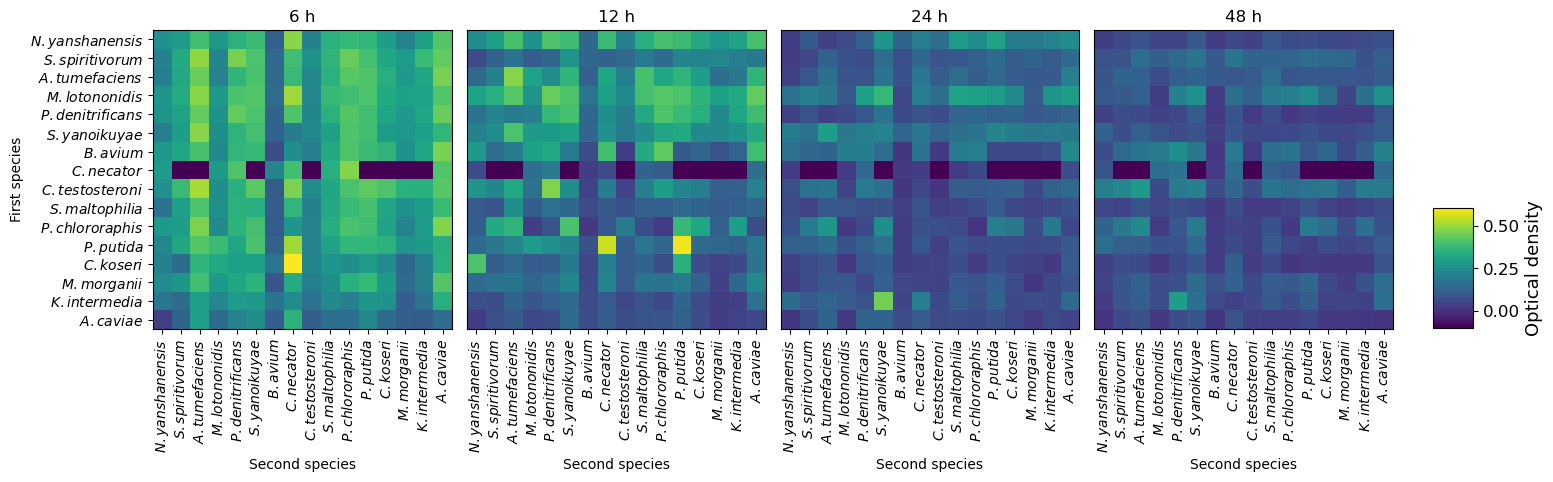

In [19]:
from mpl_toolkits.axes_grid1 import make_axes_locatable

titles = ["6 h", "12 h", "24 h", "48 h"]

vmin = np.min(flt_w_2164.to_numpy())
vmax = np.max(flt_w_2164.to_numpy())

ims = []
fig, axs = plt.subplots(1, 4, figsize=(4*4, 4))
si = 1
for df in [flt_1_w_2164, flt_2_w_2164, flt_3_w_2164, flt_4_w_2164]:
    plt.subplot(1, 4, si)
    im = plt.imshow(df.to_numpy(), vmin=vmin, vmax=vmax)
    ims.append(im)
    plt.xticks(range(len(df.columns)), ["$\it{" + SPECIES_NAMES_SHORT[str(x)] + "}$" for x in df.columns], rotation=90)
    if si == 1:
        plt.yticks(range(len(df.index)), ["$\it{" + SPECIES_NAMES_SHORT[str(x)] + "}$" for x in df.columns])
        plt.ylabel("First species")
    else:
        plt.yticks([], [])
    plt.xlabel("Second species")
    plt.title(titles[si-1])
    si += 1


cbar_ax = fig.add_axes([0.925, 0.125, 0.025, 0.3])
cbar = fig.colorbar(ims[0], cax=cbar_ax)
cbar.set_label("Optical density", fontsize=13)
cbar.ax.tick_params(labelsize=12)

plt.subplots_adjust(wspace=0.05)
plt.savefig(FIGURES_DIR/"Figure_S5.pdf", bbox_inches="tight")
plt.show()

# Figure S5

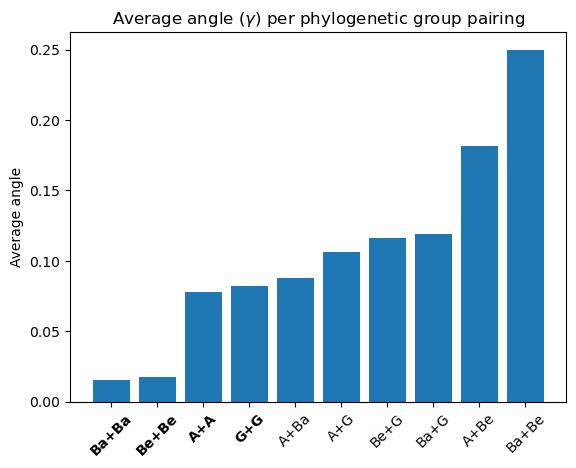

In [20]:
sorted_df = min_angle_df.sort_values("Angle")  # from Figure 5a

group_averages = pd.DataFrame(index=[x for x in np.unique(list(PHYLO_GROUP_COMBOS.values()))])
group_averages["Sum"] = 0.0
group_averages["Count"] = 0

for i in range(len(sorted_df.index)):
    idx = sorted_df.index[i]
    combo = PHYLO_GROUPS[idx.split("+")[0]] + "+" + PHYLO_GROUPS[idx.split("+")[1]]
    group_combo = PHYLO_GROUP_COMBOS[combo]
    group_averages.loc[group_combo, "Sum"] += sorted_df.loc[idx, "Angle"].astype(float)
    group_averages.loc[group_combo, "Count"] += 1

group_averages["Average"] = group_averages["Sum"]/group_averages["Count"]
group_averages = group_averages.sort_values("Average")

plt.figure()
plt.bar(group_averages.index, group_averages["Average"])

for i in range(len(group_averages.index)):
    label = group_averages.index[i]
    if label.split("+")[0] == label.split("+")[1]:
        plt.gca().get_xticklabels()[i].set_fontweight("bold")

plt.ylabel("Average angle")
plt.xticks(rotation=45)
plt.title(r"Average angle ($\gamma$) per phylogenetic group pairing")
plt.savefig(FIGURES_DIR/"Figure_S6.pdf", bbox_inches="tight")
plt.show()

# Figure S6

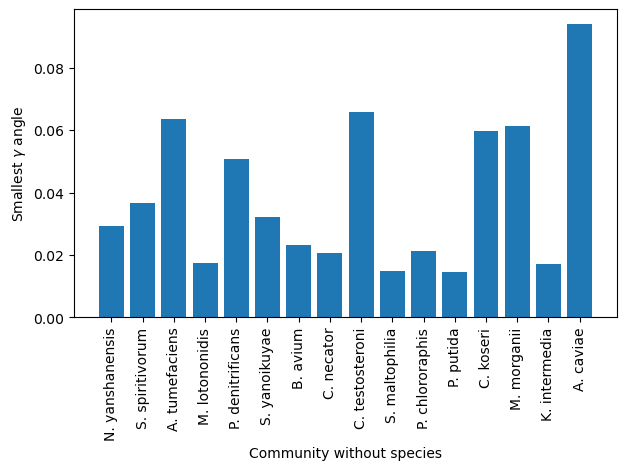

In [21]:
df = np.log(ep_nmf_nbc_acts + PSEUDOCOUNT) - np.log(ep_nmf_control_median + PSEUDOCOUNT)
ts_df = np.log(ts_nmf_nbc_acts + PSEUDOCOUNT) - np.log(ts_nmf_control_median + PSEUDOCOUNT)

min_angles = pd.DataFrame(index=["Comm-" + x for x in SPECIES_LIST.astype(str)], columns=["Angle"])

for sp in SPECIES_LIST.astype(str):
    
    loo_df = df.loc[[x for x in df.index if x.split("_")[0] == "Comm-" + sp]]
    
    ep_sp_df = df.loc[[x for x in df.index if x.split("_")[0] == sp]]
    ep_comm_df = df.loc[[x for x in df.index if x.split("_")[0] == "Comm"]]
    ts_sp_df = ts_df.loc[[x for x in ts_df.index if x.split("_")[0] == sp]]
    ts_comm_df = ts_df.loc[[x for x in ts_df.index if x.split("_")[0] == "Comm"]]

    sp_df = pd.concat([ep_sp_df, ts_sp_df])
    comm_df = pd.concat([ep_comm_df, ts_comm_df])

    angles = []
    for idx_1 in sp_df.index:
        for idx_2 in loo_df.index:
            for comm_idx in comm_df.index:
                a = sp_df.loc[idx_1].to_numpy().flatten().astype(float)
                b = loo_df.loc[idx_2].to_numpy().flatten().astype(float)
                c = comm_df.loc[comm_idx].to_numpy().flatten().astype(float)
                angles.append(gram_angle(a, b, c))

    min_angles.loc["Comm-" + sp] = np.min(angles)

order = [f"Comm-{sp}" for sp in SPECIES_ORDER]
min_angles = min_angles.loc[order]

plt.figure(figsize=(7, 4))
plt.bar(min_angles.index, min_angles["Angle"])
plt.xlabel("Community without species")
plt.ylabel(r"Smallest $\gamma$ angle")
plt.xticks(range(len(order)), [SPECIES_NAMES_SHORT[x.split("-")[1]] for x in order], rotation=90)
plt.savefig(FIGURES_DIR/"Figure_S7.pdf", bbox_inches="tight")
plt.show()

# Figure S7 and simulations

## Monoculture

In [22]:
R_0 = ep_nmf_control_median.to_numpy()
rng = np.random.default_rng(1)
sim_params = [simulate_species(R_0, rng=rng) for _ in range(16)]

maintenance_scalar = 1e-2
K = 0.1
tmax = 48*60
dt = 1

N_sims = []
R_sims = []

r_sims = []
nu_sims = []
q_sims = []
m_sims = []

for i in range(len(sim_params)):
    N0 = 0.01

    r = sim_params[i][0].copy()
    nu = sim_params[i][1].copy()
    q = sim_params[i][2]
    m = sim_params[i][3]

    r_sims.append(r.copy())
    nu_sims.append(nu.copy())
    q_sims.append(q)
    m_sims.append(m)
    
    N_curr = N0
    R_curr = R_0.copy()
    
    N_sim = [N_curr]
    R_sim = [R_curr.copy()]
    
    nsteps = int(tmax/dt)
    for t in range(nsteps):
        
        N_prev = N_curr
        N_curr += dNdt(t, r, R_curr, N_curr, q, m, K)*dt
        dN = N_curr - N_prev
        R_curr += dRdt(t, nu, R_curr, dN+(maintenance_scalar*N_curr))*dt
    
        N_sim.append(N_curr)
        R_sim.append(R_curr.copy())

    N_sims.append(N_sim)
    R_sims.append(R_sim)

## Biculture

In [23]:
emergent_pairs = [(5, 8), (10, 11), (9, 12), (8, 12), (7, 12)]

bi_R_sims = []
bi_N_sims = []
labels = []

for sp1_i in range(len(sim_params)-1):
    for sp2_i in range(sp1_i+1, len(sim_params)):
        r1 = r_sims[sp1_i].copy()
        nu1 = nu_sims[sp1_i].copy()
        q1 = q_sims[sp1_i]
        m1 = m_sims[sp1_i]
        
        r2 = r_sims[sp2_i].copy()
        nu2 = nu_sims[sp2_i].copy()
        q2 = q_sims[sp2_i]
        m2 = m_sims[sp2_i]

        # Add emergent property
        if (sp1_i, sp2_i) in emergent_pairs:
            nonzero_nu_idx = [i for i in range(len(nu1)) if nu1[i] == 0 and nu2[i] == 0]   
            emergent_resource_idx = nonzero_nu_idx[np.random.randint(len(nonzero_nu_idx))]

            r1[emergent_resource_idx] = 0
            nu1[emergent_resource_idx] = -0.8

        N0_1 = 0.01
        N0_2 = 0.01
        
        N_curr_1 = N0_1
        N_curr_2 = N0_2
        
        N_sim_1 = [N_curr_1]
        N_sim_2 = [N_curr_2]
        N_sim_b = [N_curr_1 + N_curr_2]
        
        R_curr = R_0.copy()
        R_sim = [R_curr.copy()]
        
        nsteps = int(tmax/dt)
        for t in range(nsteps):
            
            N_prev_1 = float(N_curr_1)
            N_prev_2 = float(N_curr_2)
            N_curr_1 += dNdt(t, r1, R_curr, N_curr_1, q1, m1, K) * dt
            N_curr_2 += dNdt(t, r2, R_curr, N_curr_2, q2, m2, K) * dt
            R_curr += dRdt(t, nu1, R_curr, (N_curr_1 - N_prev_1)+(maintenance_scalar*N_curr_1))*dt + dRdt(t, nu2, R_curr, (N_curr_2 - N_prev_2)+(maintenance_scalar*N_curr_2))*dt
            R_curr[R_curr < 0] = 0

            N_sim_1.append(N_curr_1)
            N_sim_2.append(N_curr_2)
            N_sim_b.append(N_curr_1 + N_curr_2)
            R_sim.append(R_curr.copy())

        labels.append(f"{sp1_i}+{sp2_i}")
        bi_R_sims.append(R_sim)
        bi_N_sims.append(N_sim)

In [24]:
ps = 1e-20  # Tiny pseudocount to avoid undefined logarithms
t_offset = -1000  # Take a time point where resource values are sufficiently high, for numerical stability
R_0 = ep_nmf_control_median.to_numpy()
bi_R_sims_final = np.array(bi_R_sims)[:, t_offset, :]
sim_species_list = np.array(range(len(R_sims))).astype(str)
emg_prop_df = pd.DataFrame(index=sim_species_list, columns=sim_species_list)
for i in range(len(sim_species_list)-1):
    sp1 = sim_species_list[i]
    for j in range(i+1, len(sim_species_list)):
        sp2 = sim_species_list[j]

        sp1_sim_R = R_sims[int(sp1)][t_offset]
        sp2_sim_R = R_sims[int(sp2)][t_offset]
        bi_sim_R = bi_R_sims_final[np.where(np.array(labels) == f"{sp1}+{sp2}")[0][0]]

        sp1_Nt = N_sims[int(sp1)]
        sp2_Nt = N_sims[int(sp2)]
        bi_Nt = bi_N_sims[np.where(np.array(labels) == f"{sp1}+{sp2}")[0][0]]
        
        nu_sp1 = (np.log(sp1_sim_R + ps) - np.log(R_0 + ps))
        nu_sp2 = (np.log(sp2_sim_R + ps) - np.log(R_0 + ps))
        nu_bi = (np.log(bi_sim_R + ps) - np.log(R_0 + ps))
        angle = gram_angle(nu_sp1, nu_sp2, nu_bi)
        emg_prop_df.loc[sp1, sp2] = angle
        emg_prop_df.loc[sp2, sp1] = angle
        emg_prop_df.loc[sp1, sp1] = 0
        emg_prop_df.loc[sp2, sp2] = 0

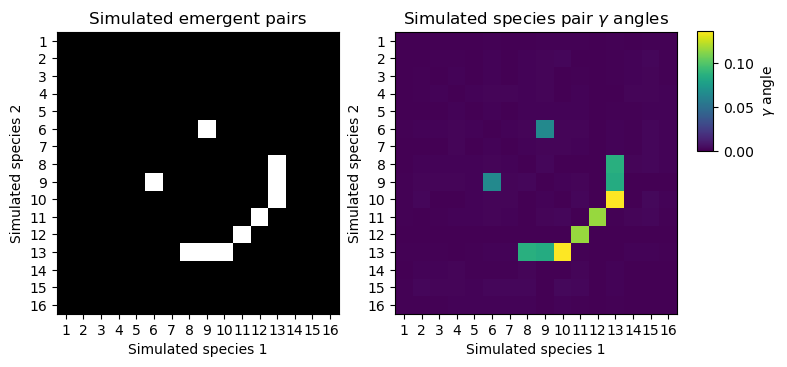

In [25]:
dummy_df = pd.DataFrame(data=np.zeros((len(sim_species_list), len(sim_species_list))), index=sim_species_list, columns=sim_species_list)
for pair in emergent_pairs:
    dummy_df.loc[str(pair[0]), str(pair[1])] = 1
    dummy_df.loc[str(pair[1]), str(pair[0])] = 1

fig, axs = plt.subplots(1, 2, figsize=(4*2, 4))
axs[0].imshow(dummy_df.to_numpy().astype(float), cmap="Greys_r")
axs[0].set_xticks(range(len(dummy_df.index)), [int(x)+1 for x in dummy_df.index])
axs[0].set_yticks(range(len(dummy_df.columns)), [int(x)+1 for x in dummy_df.index])
axs[0].set_title("Simulated emergent pairs")
axs[0].set_xlabel("Simulated species 1")
axs[0].set_ylabel("Simulated species 2")

ep_df = emg_prop_df
im = axs[1].imshow(ep_df.to_numpy().astype(float))
axs[1].set_xticks(range(len(ep_df.index)), [int(x)+1 for x in ep_df.index])
axs[1].set_yticks(range(len(ep_df.columns)), [int(x)+1 for x in ep_df.index])
axs[1].set_title(r"Simulated species pair $\gamma$ angles")
axs[1].set_xlabel("Simulated species 1")
axs[1].set_ylabel("Simulated species 2")
cbar_ax = fig.add_axes([0.925, 0.55, 0.02, 0.3])
fig.colorbar(im, cax=cbar_ax, label=r"$\gamma$ angle")

# plt.savefig("./Plots/Manuscript/Figures/v2/simulated_emergence.pdf", bbox_inches="tight")
plt.show()